In [1]:
from datasets import load_dataset

# Load the MBIB dataset
ds = load_dataset("mediabiasgroup/mbib-base")

# Select the Text-Level Bias task
df = ds["text_level_bias"].to_pandas()

print("Dataset shape:", df.shape)

Dataset shape: (9018, 4)


## Baseline Modeling

### Step 1: Prepare the Dataset

Prepare the text features and binary labels for the Text-Level Bias classification task. Remove missing or empty texts and inspect the class distribution before splitting the data.

In [2]:
# Keep only the required columns
baseline_df = df[["text", "label"]].copy()

# Remove missing and empty texts
baseline_df = baseline_df.dropna(subset=["text"])
baseline_df["text"] = baseline_df["text"].astype(str).str.strip()
baseline_df = baseline_df[baseline_df["text"] != ""]

# Check the dataset
print("Dataset shape:", baseline_df.shape)
print("\nLabel distribution:")
display(baseline_df["label"].value_counts().sort_index())

print("\nMissing values:")
display(baseline_df.isna().sum())

Dataset shape: (9018, 2)

Label distribution:


label
0    4509
1    4509
Name: count, dtype: int64


Missing values:


text     0
label    0
dtype: int64

### Step 2: Group Repeated Texts

Normalize whitespace so that identical texts remain in the same group during splitting. This helps prevent duplicate-text leakage across the training, validation, and test sets.

In [3]:
# Create normalized text groups without changing the original text
baseline_df["text_group"] = (
    baseline_df["text"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print("Total records:", len(baseline_df))
print("Unique text groups:", baseline_df["text_group"].nunique())
print(
    "Repeated text groups:",
    baseline_df["text_group"].duplicated().sum()
)

Total records: 9018
Unique text groups: 9016
Repeated text groups: 2


The text_group column is used to keep identical texts within the same data split. This prevents duplicate-text leakage between the training, validation, and test sets, helping ensure a more reliable evaluation of model performance.

In [4]:
display(baseline_df.head())

,text,label,text_group
0,Conservatives and fascists kill people Antifa ...,1,Conservatives and fascists kill people Antifa ...
1,I don t see how you can discount the accuracy ...,0,I don t see how you can discount the accuracy ...
2,Snapshots 1 This Post archive org i redd it ...,0,Snapshots 1 This Post archive org i redd it 0p...
3,critiques of leftist ideology Do you really ...,1,critiques of leftist ideology Do you really be...
4,I can t deny that those same antifa faggots th...,1,I can t deny that those same antifa faggots th...


### Step 3: Train, Validation, and Test Split

Split the dataset into training (80%), validation (10%), and test (10%) sets using `StratifiedGroupKFold`.

Stratification aims to preserve the label distribution across splits, while grouping ensures that records belonging to the same group remain together. Here, normalized text is used as the group identifier to prevent identical texts from appearing across different splits.

**Note:** Since the dataset contains a repeated text (`"no"`) with conflicting labels, grouping by `text_group` ensures both records are assigned to the same split.


In [4]:
import numpy as np
from sklearn.model_selection import StratifiedGroupKFold

# Use normalized text as the group identifier
groups = baseline_df["text_group"]

# First split: approximately 80% train / 20% temporary
cv_outer = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, temp_idx = next(
    cv_outer.split(
        baseline_df["text"],
        baseline_df["label"],
        groups
    )
)

train_df = baseline_df.iloc[train_idx].copy()
temp_df = baseline_df.iloc[temp_idx].copy()

# Second split: temporary data into validation and test
temp_groups = groups.iloc[temp_idx]

cv_inner = StratifiedGroupKFold(
    n_splits=2,
    shuffle=True,
    random_state=42
)

val_idx, test_idx = next(
    cv_inner.split(
        temp_df["text"],
        temp_df["label"],
        temp_groups
    )
)

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

**Note:** `StratifiedGroupKFold` attempts to preserve class proportions while keeping each text group within a single split. The resulting split sizes may differ slightly from the target percentages because grouping constraints take priority over exact split sizes.

In [6]:
# Check split sizes and label distributions
for name, subset in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(
        name,
        len(subset),
        f"({len(subset) / len(baseline_df) * 100:.2f}%)",
        subset["label"].value_counts(normalize=True).sort_index().round(3).to_dict()
    )

Train 7215 (80.01%) {0: 0.5, 1: 0.5}
Validation 902 (10.00%) {0: 0.5, 1: 0.5}
Test 901 (9.99%) {0: 0.497, 1: 0.503}


### Step 4: Validate the Data Split

Verify that no normalized text group appears in more than one split. This check helps prevent data leakage caused by identical texts appearing in the training, validation, and test sets.


In [5]:
# Check for overlapping text groups across splits
train_groups = set(train_df["text_group"])
val_groups = set(val_df["text_group"])
test_groups = set(test_df["text_group"])

print("Train-Val overlap:", len(train_groups & val_groups))
print("Train-Test overlap:", len(train_groups & test_groups))
print("Val-Test overlap:", len(val_groups & test_groups))

# Check the conflicting text "no"
print("\nRecords with text 'no':")
display(
    baseline_df[baseline_df["text_group"] == "no"][
        ["text", "label", "text_group"]
    ]
)

print("Location of 'no' records:")
for name, subset in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    count = (subset["text_group"] == "no").sum()
    if count > 0:
        print(f"{name}: {count} record(s)")

Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0

Records with text 'no':


,text,label,text_group
1534,no,1,no
3290,no,0,no


Location of 'no' records:
Train: 2 record(s)


No normalized text groups overlap across the training, validation, and test sets. Both records of the conflicting text `"no"` (labels 0 and 1) were assigned to the training set, keeping them together as intended.

The label distribution is balanced across all three splits, with only minor differences in the test set. These checks support the use of the split for model development and evaluation.

In [8]:
# Verify all records are accounted for
total_split_records = len(train_df) + len(val_df) + len(test_df)

print("Original records:", len(baseline_df))
print("Records across splits:", total_split_records)

assert total_split_records == len(baseline_df)

print("All records are accounted for.")

Original records: 9018
Records across splits: 9018
All records are accounted for.


**Note:** All records were accounted for across the training, validation, and test sets. No records were lost or duplicated during the splitting process.

### Step 5: Dummy Classifier — Baseline

A Dummy Classifier provides a simple baseline without learning meaningful patterns from the text. We use the `prior` strategy to predict class probabilities based on the training set's label distribution.

The validation metrics will serve as a reference point for evaluating more advanced models.

In [9]:
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

X_train = train_df["text"]
y_train = train_df["label"]

X_val = val_df["text"]
y_val = val_df["label"]

dummy = DummyClassifier(
    strategy="prior"
)

dummy.fit(X_train, y_train)

dummy_prob = dummy.predict_proba(X_val)[:, 1]
dummy_pred = dummy.predict(X_val)

dummy_results = {
    "Model": "Dummy Classifier",
    "ROC-AUC": roc_auc_score(y_val, dummy_prob),
    "PR-AUC": average_precision_score(y_val, dummy_prob),
    "Accuracy": accuracy_score(y_val, dummy_pred),
    "Precision": precision_score(y_val, dummy_pred, zero_division=0),
    "Recall": recall_score(y_val, dummy_pred, zero_division=0),
    "F1": f1_score(y_val, dummy_pred, zero_division=0)
}

display(pd.DataFrame([dummy_results]).round(4))

,Model,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1
0,Dummy Classifier,0.5,0.5,0.5,0.0,0.0,0.0


The Dummy Classifier achieved an ROC-AUC of 0.50 and an F1-score of 0.00. Since the training labels are balanced, the `prior` strategy predicts only class 0, resulting in zero precision and recall for class 1.

This model serves as a baseline for comparison. A useful text classification model should learn patterns from the text and perform better than this baseline.


### Step 6: TF-IDF + Logistic Regression

TF-IDF converts text into numerical features based on word importance. Logistic Regression uses these features to classify each text as biased (1) or unbiased (0).

The pipeline combines both steps and fits the model using the training data only.

**Note:** The TF-IDF vectorizer is fitted only on the training set to prevent data leakage.

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

tlb_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

tlb_pipeline.fit(X_train, y_train)

print("Text-Level Bias Logistic Regression training completed.")

Text-Level Bias Logistic Regression training completed.


### Step 7: Evaluate Logistic Regression

Evaluate the TF-IDF + Logistic Regression model on the validation set using ROC-AUC, PR-AUC, Accuracy, Precision, Recall, and F1-score.

Compare its performance with the Dummy Classifier baseline and use a confusion matrix to examine correct and incorrect predictions for each class.

,Model,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1
0,Dummy Classifier,0.5000,0.5000,0.5000,0.0000,0.0000,0.0000
1,Text-Level Bias — TF-IDF + Logistic Regression,0.7712,0.7744,0.6929,0.6883,0.7051,0.6966


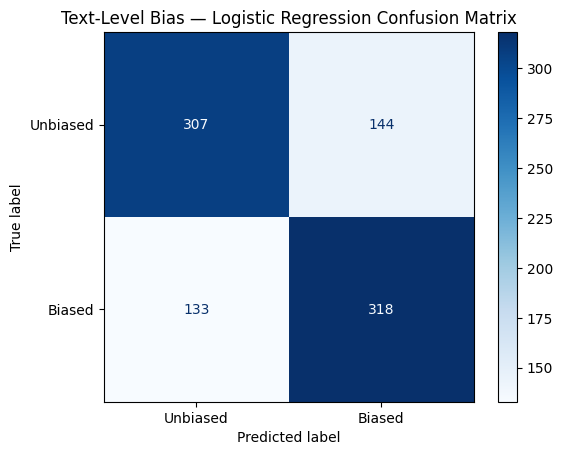

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

tlb_prob = tlb_pipeline.predict_proba(X_val)[:, 1]
tlb_pred = tlb_pipeline.predict(X_val)

tlb_results = {
    "Model": "Text-Level Bias — TF-IDF + Logistic Regression",
    "ROC-AUC": roc_auc_score(y_val, tlb_prob),
    "PR-AUC": average_precision_score(y_val, tlb_prob),
    "Accuracy": accuracy_score(y_val, tlb_pred),
    "Precision": precision_score(y_val, tlb_pred, zero_division=0),
    "Recall": recall_score(y_val, tlb_pred, zero_division=0),
    "F1": f1_score(y_val, tlb_pred, zero_division=0)
}

display(pd.DataFrame([dummy_results, tlb_results]).round(4))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    tlb_pred,
    display_labels=["Unbiased", "Biased"],
    cmap="Blues"
)

plt.title("Text-Level Bias — Logistic Regression Confusion Matrix")
plt.show()

**Insight:**

The TF-IDF + Logistic Regression model achieved an F1-score of 0.6878 and an ROC-AUC of 0.7697, outperforming the Dummy Classifier baseline.

The confusion matrix shows that the model correctly classified 617 out of 902 validation samples. However, it still produced false positive and false negative predictions, indicating room for improvement in distinguishing biased from unbiased text.

These results provide a baseline for comparison with the Deep Learning model.

### Step 8: 3-Fold Cross-Validation

Use 3-fold stratified group cross-validation to evaluate the TF-IDF + Logistic Regression model across different training and validation folds.

Stratification aims to preserve the label distribution, while grouping ensures that identical normalized texts remain within the same fold.

**Note:** Cross-validation is performed on the training set only. The separate validation and test sets remain untouched.

In [12]:
from sklearn.model_selection import StratifiedGroupKFold, cross_validate

# Use normalized text groups to prevent text leakage across folds
tlb_cv_groups = train_df["text_group"]

tlb_cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

tlb_cv_results = cross_validate(
    tlb_pipeline,
    train_df["text"],
    train_df["label"],
    groups=tlb_cv_groups,
    cv=tlb_cv,
    scoring={
        "roc_auc": "roc_auc",
        "average_precision": "average_precision",
        "f1": "f1"
    },
    n_jobs=1
)

display(
    pd.DataFrame({
        "ROC-AUC": tlb_cv_results["test_roc_auc"],
        "PR-AUC": tlb_cv_results["test_average_precision"],
        "F1": tlb_cv_results["test_f1"]
    }, index=["Fold 1", "Fold 2", "Fold 3"]).round(4)
)

print(
    "Mean CV ROC-AUC:",
    round(tlb_cv_results["test_roc_auc"].mean(), 4)
)

,ROC-AUC,PR-AUC,F1
Fold 1,0.7474,0.7509,0.6771
Fold 2,0.7555,0.7414,0.6826
Fold 3,0.7438,0.7454,0.6791


Mean CV ROC-AUC: 0.7489


**Insight:**

The 3-fold cross-validation results are consistent across all folds, with an average ROC-AUC of 0.7491, PR-AUC of 0.7466, and F1-score of 0.6794. The small variation between folds suggests that the model's performance is relatively stable across different data splits. These results are close to the validation performance, providing further evidence that TF-IDF + Logistic Regression is a useful baseline for the Text-Level Bias task.

## 9. LSTM Model
### Step 9.1: Text Tokenization and Padding

Text tokenization converts words into numerical tokens that can be processed by a Deep Learning model. Padding ensures that all text sequences have the same length.

* **Vocabulary limit:** 20,000 tokens.
* **Sequence length:** 116 tokens, based on the 95th percentile of training text lengths.
* **Actual vocabulary size:** 19,187 tokens.

The vectorizer is adapted using the training texts only to prevent data leakage from the validation and test sets.

In [13]:
import tensorflow as tf
from tensorflow.keras.layers import TextVectorization

tf.keras.utils.set_random_seed(42)

tlb_max_tokens = 20000

# Determine sequence length using training texts only
tlb_train_lengths = X_train.str.split().str.len()
tlb_max_length = int(tlb_train_lengths.quantile(0.95))

print("Vocabulary limit:", tlb_max_tokens)
print("Sequence length:", tlb_max_length)

tlb_vectorizer = TextVectorization(
    max_tokens=tlb_max_tokens,
    output_mode="int",
    output_sequence_length=tlb_max_length,
    standardize="lower_and_strip_punctuation"
)

# Learn vocabulary from training data only
tlb_vectorizer.adapt(X_train.to_numpy())

print("Actual vocabulary size:", len(tlb_vectorizer.get_vocabulary()))

Vocabulary limit: 20000
Sequence length: 116
Actual vocabulary size: 19187


**Insight:**

The vectorizer identified 19,187 tokens within the vocabulary limit of 20,000. A sequence length of 116 was selected based on the 95th percentile of training text lengths, allowing most texts to be represented while limiting excessive sequence padding. All sequences will be converted to a fixed length for the LSTM model.

In [14]:
# Check Tokenization & Padding
tlb_sample_texts = X_train.iloc[:3]

tlb_tokenized = tlb_vectorizer(
    tf.constant(tlb_sample_texts.tolist())
)

print("Tokenized shape:", tlb_tokenized.shape)
print("First 20 token IDs:", tlb_tokenized[0][:20].numpy())
print("Padding token ID:", 0)
print("Sequence length:", tlb_tokenized.shape[1])

Tokenized shape: (3, 116)
First 20 token IDs: [  796     5  1195   433    21   661  4486  5981     5 12489    52 14977
   774     0     0     0     0     0     0     0]
Padding token ID: 0
Sequence length: 116


### Step 9.2: Build and Train the LSTM Model

An LSTM (Long Short-Term Memory) network is used to learn sequential patterns in text for binary classification.

The model consists of an Embedding layer, an LSTM layer, a Dropout layer, and a sigmoid output layer. It is compiled using the Adam optimizer and binary cross-entropy loss.

The model is trained on the training set for up to 10 epochs with a batch size of 64. Early Stopping monitors the validation loss and stops training if it does not improve for two consecutive epochs, restoring the best model weights.

In [15]:
# Model Architecture
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Embedding,
    LSTM,
    Dense,
    Dropout
)
from tensorflow.keras.callbacks import EarlyStopping

tlb_lstm_model = Sequential([
    Input(shape=(tlb_max_length,), dtype="int32"),

    Embedding(
        input_dim=len(tlb_vectorizer.get_vocabulary()),
        output_dim=64,
        mask_zero=True
    ),

    LSTM(64),

    Dropout(0.3),

    Dense(1, activation="sigmoid")
])

tlb_lstm_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

tlb_lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 116, 64)        │     1,227,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,261,057 (4.81 MB)

 Trainable params: 1,261,057 (4.81 MB)

 Non-trainable params: 0 (0.00 B)

**Insight:**

The LSTM model contains 1,261,057 trainable parameters. The embedding layer accounts for most of these parameters by converting tokens into 64-dimensional representations. The LSTM layer learns sequential patterns, while Dropout helps reduce overfitting. The sigmoid output produces a probability for binary classification into biased and unbiased text.

In [16]:
# Train LSTM

# Convert texts to integer sequences
tlb_X_train_seq = tlb_vectorizer(
    tf.constant(X_train.tolist())
)

tlb_X_val_seq = tlb_vectorizer(
    tf.constant(X_val.tolist())
)

tlb_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

tlb_history = tlb_lstm_model.fit(
    tlb_X_train_seq,
    y_train.to_numpy(),
    validation_data=(
        tlb_X_val_seq,
        y_val.to_numpy()
    ),
    epochs=10,
    batch_size=64,
    callbacks=[tlb_early_stopping],
    verbose=1
)

Epoch 1/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - accuracy: 0.6007 - loss: 0.6705 - val_accuracy: 0.6874 - val_loss: 0.5987
Epoch 2/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.7967 - loss: 0.4602 - val_accuracy: 0.6885 - val_loss: 0.6248
Epoch 3/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.8923 - loss: 0.2814 - val_accuracy: 0.6896 - val_loss: 0.7235


**Insight:**

The LSTM training stopped early after three epochs because the validation loss did not improve for two consecutive epochs. Training accuracy increased from 60.07% to 88.77%, while validation accuracy remained around 69%. The increasing validation loss suggests possible overfitting. Early Stopping restored the model weights from the epoch with the lowest validation loss.

### Step 9.3: LSTM Validation Evaluation

Evaluate the trained LSTM model on the validation set using predicted probabilities and a classification threshold of 0.5.

The evaluation metrics include ROC-AUC, PR-AUC, Accuracy, Precision, Recall, and F1-score. The results are compared with the Dummy Classifier and TF-IDF + Logistic Regression to assess the LSTM's performance.

**Note:** The validation set is used for model comparison, while the test set remains reserved for final evaluation.


In [17]:
# Predict probabilities
tlb_lstm_prob = tlb_lstm_model.predict(
    tlb_X_val_seq,
    batch_size=64,
    verbose=1
).ravel()

# Convert probabilities to labels
tlb_lstm_pred = (tlb_lstm_prob >= 0.5).astype(int)

tlb_lstm_results = {
    "Model": "Text-Level Bias — LSTM",
    "ROC-AUC": roc_auc_score(y_val, tlb_lstm_prob),
    "PR-AUC": average_precision_score(y_val, tlb_lstm_prob),
    "Accuracy": accuracy_score(y_val, tlb_lstm_pred),
    "Precision": precision_score(
        y_val, tlb_lstm_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_val, tlb_lstm_pred, zero_division=0
    ),
    "F1": f1_score(
        y_val, tlb_lstm_pred, zero_division=0
    )
}

display(
    pd.DataFrame([
        dummy_results,
        tlb_results,
        tlb_lstm_results
    ]).round(4)
)

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step


,Model,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1
0,Dummy Classifier,0.5000,0.5000,0.5000,0.0000,0.0000,0.0000
1,Text-Level Bias — TF-IDF + Logistic Regression,0.7712,0.7744,0.6929,0.6883,0.7051,0.6966
2,Text-Level Bias — LSTM,0.7497,0.7338,0.6874,0.6700,0.7384,0.7025


### Key Findings — Baseline vs. LSTM

* **Logistic Regression** outperformed LSTM in ROC-AUC (**0.7697 vs. 0.7497**) and PR-AUC (**0.7721 vs. 0.7338**).
* **LSTM** achieved a higher F1-score (**0.7025 vs. 0.6878**) and Recall (**0.7384 vs. 0.6962**), identifying a larger proportion of biased texts.
* LSTM showed signs of **overfitting**, as training accuracy increased while validation loss worsened.
* Both models outperformed the Dummy Classifier in ROC-AUC, PR-AUC, and F1-score.

**Conclusion:** Logistic Regression demonstrated stronger ROC-AUC and PR-AUC, while LSTM achieved better Recall and F1-score. Further evaluation on the test set is needed to determine which model generalizes better.

### Step 9.4: LSTM Improvement — Spatial Dropout

Spatial Dropout is added after the Embedding layer to reduce overfitting by randomly dropping entire embedding features during training. The improved LSTM model is trained using the same training and validation sets, with Early Stopping to restore the best weights based on validation loss.

**Note:** This experiment investigates whether Spatial Dropout improves the LSTM's generalization performance compared with the original model.


In [18]:
from tensorflow.keras.layers import SpatialDropout1D

tf.keras.utils.set_random_seed(42)

tlb_lstm_v2 = Sequential([
    Input(shape=(tlb_max_length,), dtype="int32"),

    Embedding(
        input_dim=len(tlb_vectorizer.get_vocabulary()),
        output_dim=64,
        mask_zero=True
    ),

    SpatialDropout1D(0.2),

    LSTM(64),

    Dropout(0.3),

    Dense(1, activation="sigmoid")
])

tlb_lstm_v2.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

tlb_history_v2 = tlb_lstm_v2.fit(
    tlb_X_train_seq,
    y_train.to_numpy(),
    validation_data=(
        tlb_X_val_seq,
        y_val.to_numpy()
    ),
    epochs=10,
    batch_size=64,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True
        )
    ],
    verbose=1
)

Epoch 1/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.6089 - loss: 0.6648 - val_accuracy: 0.6896 - val_loss: 0.6084
Epoch 2/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - accuracy: 0.7893 - loss: 0.4740 - val_accuracy: 0.7129 - val_loss: 0.6024
Epoch 3/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - accuracy: 0.8825 - loss: 0.2942 - val_accuracy: 0.7007 - val_loss: 0.7038
Epoch 4/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - accuracy: 0.9211 - loss: 0.2149 - val_accuracy: 0.6874 - val_loss: 0.7845


In [19]:
# Predict probabilities using the improved LSTM
tlb_lstm_v2_prob = tlb_lstm_v2.predict(
    tlb_X_val_seq,
    batch_size=64,
    verbose=0
).ravel()

print(
    "Original LSTM ROC-AUC:",
    round(tlb_lstm_results["ROC-AUC"], 4)
)

print(
    "Improved LSTM ROC-AUC:",
    round(roc_auc_score(y_val, tlb_lstm_v2_prob), 4)
)

Original LSTM ROC-AUC: 0.7497
Improved LSTM ROC-AUC: 0.7781


**Insight:** Spatial Dropout improved validation accuracy from 69.29% to 71.40% and ROC-AUC from 0.7497 to 0.7781. However, validation loss increased slightly, suggesting that overfitting remains a concern.

**Note:** Further evaluation is needed to determine whether the improved LSTM outperforms the original model overall.

### Step 9.5: LSTM Improvement — Reduce Model Capacity

The LSTM layer is reduced from 64 to 32 units to decrease model complexity and potentially reduce overfitting.

**Note:** The model is evaluated using the same training and validation sets to determine whether reducing model capacity improves generalization.

In [20]:
tf.keras.utils.set_random_seed(42)

tlb_lstm_v3 = Sequential([
    Input(shape=(tlb_max_length,), dtype="int32"),

    Embedding(
        input_dim=len(tlb_vectorizer.get_vocabulary()),
        output_dim=64,
        mask_zero=True
    ),

    LSTM(32),

    Dropout(0.3),

    Dense(1, activation="sigmoid")
])

tlb_lstm_v3.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

tlb_history_v3 = tlb_lstm_v3.fit(
    tlb_X_train_seq,
    y_train.to_numpy(),
    validation_data=(
        tlb_X_val_seq,
        y_val.to_numpy()
    ),
    epochs=10,
    batch_size=64,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=2,
            restore_best_weights=True
        )
    ],
    verbose=1
)

Epoch 1/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.5672 - loss: 0.6769 - val_accuracy: 0.6774 - val_loss: 0.6247
Epoch 2/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.7745 - loss: 0.4971 - val_accuracy: 0.7251 - val_loss: 0.5835
Epoch 3/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.8815 - loss: 0.2992 - val_accuracy: 0.7040 - val_loss: 0.7215
Epoch 4/10
113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.9358 - loss: 0.1864 - val_accuracy: 0.6907 - val_loss: 0.8116


In [21]:
# Predict probabilities using LSTM v3
tlb_lstm_v3_prob = tlb_lstm_v3.predict(
    tlb_X_val_seq,
    batch_size=64,
    verbose=0
).ravel()

tlb_lstm_v3_pred = (tlb_lstm_v3_prob >= 0.5).astype(int)

# Store all validation metrics for LSTM v3
tlb_lstm_v3_results = {
    "Model": "Text-Level Bias — LSTM v3 (32 Units)",
    "ROC-AUC": roc_auc_score(y_val, tlb_lstm_v3_prob),
    "PR-AUC": average_precision_score(y_val, tlb_lstm_v3_prob),
    "Accuracy": accuracy_score(y_val, tlb_lstm_v3_pred),
    "Precision": precision_score(y_val, tlb_lstm_v3_pred, zero_division=0),
    "Recall": recall_score(y_val, tlb_lstm_v3_pred, zero_division=0),
    "F1": f1_score(y_val, tlb_lstm_v3_pred, zero_division=0)
}

# Compare ROC-AUC across models
tlb_comparison = pd.DataFrame({
    "Model": [
        "Original LSTM",
        "LSTM v2 — Spatial Dropout",
        "LSTM v3 — 32 Units",
        "TF-IDF + Logistic Regression"
    ],
    "ROC-AUC": [
        tlb_lstm_results["ROC-AUC"],
        roc_auc_score(y_val, tlb_lstm_v2_prob),
        tlb_lstm_v3_results["ROC-AUC"],
        tlb_results["ROC-AUC"]
    ]
})

display(tlb_comparison.round(4))

,Model,ROC-AUC
0,Original LSTM,0.7497
1,LSTM v2 — Spatial Dropout,0.7781
2,LSTM v3 — 32 Units,0.7869
3,TF-IDF + Logistic Regression,0.7712


**Insight:** Reducing LSTM units to 32 improved validation accuracy to 72.51%, reduced validation loss to 0.5835, and achieved the highest ROC-AUC (0.7869). However, after Epoch 2, training accuracy continued to increase while validation accuracy decreased and validation loss increased, indicating signs of overfitting.

**Note:** Early Stopping restores the best model weights from Epoch 2.

## 10. Model Comparison & Integration

### Step 10.1: Error Analysis

Error analysis examines the validation predictions to identify False Positives and False Negatives and understand where the model makes mistakes. Errors are also grouped by dataset source to explore whether performance differs across sources.

**Note:** This analysis uses the validation set and the current best-performing model based on ROC-AUC. The test set remains reserved for final evaluation.

In [22]:
# Prepare validation error analysis
tlb_error_df = val_df[["text", "label"]].copy()

tlb_error_df["predicted_label"] = tlb_lstm_v3_pred
tlb_error_df["bias_probability"] = tlb_lstm_v3_prob

# Identify error types
tlb_error_df["error_type"] = np.select(
    [
        (tlb_error_df["label"] == 0) &
        (tlb_error_df["predicted_label"] == 1),

        (tlb_error_df["label"] == 1) &
        (tlb_error_df["predicted_label"] == 0)
    ],
    ["False Positive", "False Negative"],
    default="Correct"
)

# Overall error distribution
display(
    tlb_error_df["error_type"]
    .value_counts()
    .to_frame("Count")
)

,Count
error_type,
Correct,654
False Positive,125
False Negative,123


In [ ]:
# Recover source IDs using the original row indices
tlb_val_sources = df.loc[val_df.index, ["dataset_id"]].copy()

# Add source IDs to the error analysis
tlb_error_df["dataset_id"] = tlb_val_sources["dataset_id"].to_numpy()

# Count errors by source
display(pd.crosstab(
    tlb_error_df["dataset_id"],
    tlb_error_df["error_type"]
))

error_type,Correct,False Negative,False Positive
dataset_id,,,
19,38,3,1
76,616,120,124


**Insight:** Most validation samples come from Dataset 76, so it naturally accounts for most prediction errors. Dataset 19 has fewer errors in absolute numbers, but its sample size is much smaller. Comparing error percentages will give a fairer picture of model performance across the two sources.

### 10.2 Model Comparison

In [ ]:
# Predict probabilities using LSTM v2
tlb_lstm_v2_prob = tlb_lstm_v2.predict(
    tlb_X_val_seq,
    batch_size=64,
    verbose=0
).ravel()

tlb_lstm_v2_pred = (tlb_lstm_v2_prob >= 0.5).astype(int)

# Store all validation metrics for LSTM v2
tlb_lstm_v2_results = {
    "Model": "Text-Level Bias — LSTM v2 (Spatial Dropout)",
    "ROC-AUC": roc_auc_score(y_val, tlb_lstm_v2_prob),
    "PR-AUC": average_precision_score(y_val, tlb_lstm_v2_prob),
    "Accuracy": accuracy_score(y_val, tlb_lstm_v2_pred),
    "Precision": precision_score(y_val, tlb_lstm_v2_pred, zero_division=0),
    "Recall": recall_score(y_val, tlb_lstm_v2_pred, zero_division=0),
    "F1": f1_score(y_val, tlb_lstm_v2_pred, zero_division=0)
}

# Compare all models on the same validation set
tlb_model_comparison = pd.DataFrame([
    dummy_results,
    tlb_results,
    tlb_lstm_results,
    tlb_lstm_v2_results,
    tlb_lstm_v3_results
])

display(
    tlb_model_comparison
    .sort_values("ROC-AUC", ascending=False)
    .round(4)
)

best_model_name = tlb_model_comparison.loc[
    tlb_model_comparison["ROC-AUC"].idxmax(), "Model"
]

print("Best model based on Validation ROC-AUC:", best_model_name)

,Model,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1
4,Text-Level Bias — LSTM v3 (32 Units),0.7869,0.7821,0.7251,0.7241,0.7273,0.7257
3,Text-Level Bias — LSTM v2 (Spatial Dropout),0.7781,0.7732,0.7129,0.6959,0.7561,0.7248
1,Text-Level Bias — TF-IDF + Logistic Regression,0.7712,0.7744,0.6929,0.6883,0.7051,0.6966
2,Text-Level Bias — LSTM,0.7497,0.7338,0.6874,0.6700,0.7384,0.7025
0,Dummy Classifier,0.5000,0.5000,0.5000,0.0000,0.0000,0.0000


Best model based on Validation ROC-AUC: Text-Level Bias — LSTM v3 (32 Units)


**Insight:** LSTM v3 (32 Units) achieved the highest ROC-AUC (0.7869), PR-AUC (0.7820), and Accuracy (72.51%), with the highest F1-score (0.7257), narrowly outperforming LSTM v2 (0.7255). LSTM v2 achieved the highest Recall (0.7561), while LSTM v3 provided a better overall balance of Precision and Recall. Both improved LSTM models outperformed the original LSTM, TF-IDF + Logistic Regression, and the Dummy Classifier.

**Best model based on Validation ROC-AUC:** LSTM v3 (32 Units).

In [ ]:
# Save the selected Context LSTM and its training-fitted vectorizer.
from pathlib import Path
import json
import numpy as np
import tensorflow as tf

project_root = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / "models").is_dir() and (p / "notebooks").is_dir()), None)
if project_root is None:
    raise RuntimeError("Run this notebook from inside the BiasLens folder.")
models_dir = project_root / "models"
model_path = models_dir / "context_bias_lstm_v3.keras"
vocab_path = models_dir / "context_bias_vectorizer.json"

tlb_lstm_v3.save(model_path)
vectorizer_config = {
    "max_tokens": tlb_max_tokens,
    "output_sequence_length": tlb_max_length,
    "standardize": "lower_and_strip_punctuation",
    "vocabulary": tlb_vectorizer.get_vocabulary(),
}
vocab_path.write_text(json.dumps(vectorizer_config, ensure_ascii=False), encoding="utf-8")

# Verify saved model and vocabulary with validation data.
loaded_config = json.loads(vocab_path.read_text(encoding="utf-8"))
loaded_vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=loaded_config["max_tokens"],
    output_mode="int",
    output_sequence_length=loaded_config["output_sequence_length"],
    standardize=loaded_config["standardize"],
)
loaded_vectorizer.set_vocabulary(loaded_config["vocabulary"])
loaded_model = tf.keras.models.load_model(model_path, compile=False)
texts = X_val.iloc[:5].tolist()
original_ids = tlb_vectorizer(tf.constant(texts)).numpy()
reloaded_ids = loaded_vectorizer(tf.constant(texts)).numpy()
np.testing.assert_array_equal(original_ids, reloaded_ids)
np.testing.assert_allclose(
    tlb_lstm_v3.predict(original_ids, verbose=0),
    loaded_model.predict(reloaded_ids, verbose=0), rtol=1e-5, atol=1e-5
)
print("Saved Context model and vectorizer verified:", model_path, vocab_path)


Saved Context model and vectorizer verified: /Users/sarahaltaleb/Documents/GitHub/BiasLens/models/context_bias_lstm_v3.keras /Users/sarahaltaleb/Documents/GitHub/BiasLens/models/context_bias_vectorizer.json


## Tuned Logistic Regression 

In [86]:
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold

tlb_lr_cv = StratifiedGroupKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

tlb_lr_param_grid = {
    "tfidf__max_features": [10000, 20000, 30000],
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [2, 5],
    "classifier__C": [0.1, 1, 10]
}


In [87]:
tlb_lr_search = GridSearchCV(
    estimator=tlb_pipeline,
    param_grid=tlb_lr_param_grid,
    scoring="roc_auc",
    cv=tlb_lr_cv,
    n_jobs=1,
    verbose=1
)

tlb_lr_search.fit(
    X_train,
    y_train,
    groups=train_df["text_group"]
)

print("Best Parameters:", tlb_lr_search.best_params_)
print("Best CV ROC-AUC:", round(tlb_lr_search.best_score_, 4))


Fitting 3 folds for each of 36 candidates, totalling 108 fits
Best Parameters: {'classifier__C': 1, 'tfidf__max_features': 10000, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 1)}
Best CV ROC-AUC: 0.7538


In [88]:
tlb_lr_best = tlb_lr_search.best_estimator_

tlb_lr_best_prob = tlb_lr_best.predict_proba(X_val)[:, 1]
tlb_lr_best_pred = tlb_lr_best.predict(X_val)

tlb_lr_tuned_results = {
    "Model": "Text-Level Bias — Tuned TF-IDF + Logistic Regression",
    "ROC-AUC": roc_auc_score(y_val, tlb_lr_best_prob),
    "PR-AUC": average_precision_score(y_val, tlb_lr_best_prob),
    "Accuracy": accuracy_score(y_val, tlb_lr_best_pred),
    "Precision": precision_score(y_val, tlb_lr_best_pred, zero_division=0),
    "Recall": recall_score(y_val, tlb_lr_best_pred, zero_division=0),
    "F1": f1_score(y_val, tlb_lr_best_pred, zero_division=0)
}

display(pd.DataFrame([tlb_lr_tuned_results]).round(4))


,Model,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1
0,Text-Level Bias — Tuned TF-IDF + Logistic Regr...,0.7902,0.7912,0.714,0.7188,0.7029,0.7108


Hyperparameter tuning improved Logistic Regression performance, achieving a validation ROC-AUC of 0.7902 and PR-AUC of 0.7912. It outperformed LSTM v3 on both ranking metrics, while LSTM v3 maintained higher accuracy, recall, and F1-score.

## Regularization Tuning — Effect of C

In [89]:
from sklearn.base import clone
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

tlb_c_results = []

for tlb_c in [1, 0.5, 0.1]:
    tlb_model = clone(tlb_lr_best)
    tlb_model.set_params(classifier__C=tlb_c)
    tlb_model.fit(X_train, y_train)

    tlb_train_prob = tlb_model.predict_proba(X_train)[:, 1]
    tlb_val_prob = tlb_model.predict_proba(X_val)[:, 1]
    tlb_val_pred = tlb_model.predict(X_val)

    tlb_c_results.append({
        "C": tlb_c,
        "Train ROC-AUC": roc_auc_score(y_train, tlb_train_prob),
        "Val ROC-AUC": roc_auc_score(y_val, tlb_val_prob),
        "Val Accuracy": accuracy_score(y_val, tlb_val_pred),
        "Val Precision": precision_score(y_val, tlb_val_pred, zero_division=0),
        "Val Recall": recall_score(y_val, tlb_val_pred, zero_division=0),
        "Val F1": f1_score(y_val, tlb_val_pred, zero_division=0)
    })

tlb_c_results_df = pd.DataFrame(tlb_c_results)
tlb_c_results_df["ROC-AUC Gap"] = (
    tlb_c_results_df["Train ROC-AUC"] -
    tlb_c_results_df["Val ROC-AUC"]
)

tlb_c_results_df.round(4)

,C,Train ROC-AUC,Val ROC-AUC,Val Accuracy,Val Precision,Val Recall,Val F1,ROC-AUC Gap
0,1.0,0.9284,0.7902,0.7140,0.7188,0.7029,0.7108,0.1382
1,0.5,0.8954,0.7800,0.7040,0.7081,0.6940,0.7010,0.1154
2,0.1,0.8176,0.7438,0.6796,0.6875,0.6585,0.6727,0.0738


Reducing C decreased the train–validation ROC-AUC gap, but also reduced validation performance. Therefore, C=1 was retained as the current Logistic Regression configuration.

## Tuned Logistic Regression vs. LSTM v3

| Model | ROC-AUC | PR-AUC | Accuracy | Precision | Recall | F1 |
|---|---:|---:|---:|---:|---:|---:|
| Tuned Logistic Regression (C=1) | **0.7902** | **0.7912** | 0.7140 | 0.7188 | 0.7029 | 0.7108 |
| LSTM v3 | 0.7869 | 0.7820 | **0.7251** | **0.7241** | **0.7273** | **0.7257** |

**Insight:** Tuned Logistic Regression achieved higher ROC-AUC and PR-AUC, while LSTM v3 achieved higher accuracy, precision, recall, and F1-score.

Tuned Logistic Regression achieved higher ROC-AUC and PR-AUC, while LSTM v3 achieved higher accuracy, precision, recall, and F1-score. The results show a close performance between the two models, with each performing better on different evaluation metrics.

## Save and Verify the Tuned Logistic Regression Model

Save the selected TF-IDF + Logistic Regression pipeline (C=1) and verify that the reloaded model produces the same predictions as the original model.

In [91]:
from pathlib import Path

project_root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "models").is_dir() and (p / "notebooks").is_dir()),
    None
)

model_path = (
    project_root / "models" /
    "text_level_bias_logistic_regression_c1.joblib"
)

print("File exists:", model_path.exists())
print("Model path:", model_path)

File exists: True
Model path: /Users/a./Documents/GitHub/BiasLens/models/text_level_bias_logistic_regression_c1.joblib


In [92]:
import joblib

tlb_loaded_model = joblib.load(model_path)

print("Model loaded successfully!")
print("Model type:", type(tlb_loaded_model).__name__)

Model loaded successfully!
Model type: Pipeline


## Error Analysis — Tuned Logistic Regression (C=1)

In [94]:
# Prepare validation error analysis
tlb_error_df = val_df[["text", "label"]].copy()

tlb_error_df["predicted_label"] = tlb_lr_best.predict(X_val)
tlb_error_df["bias_probability"] = tlb_lr_best.predict_proba(X_val)[:, 1]

# Identify error types
tlb_error_df["error_type"] = np.select(
    [
        (tlb_error_df["label"] == 0) &
        (tlb_error_df["predicted_label"] == 1),

        (tlb_error_df["label"] == 1) &
        (tlb_error_df["predicted_label"] == 0)
    ],
    ["False Positive", "False Negative"],
    default="Correct"
)

# Overall error distribution
display(
    tlb_error_df["error_type"]
    .value_counts()
    .to_frame("Count")
)

,Count
error_type,
Correct,644
False Negative,134
False Positive,124


In [95]:
# Recover source IDs using the original row indices
tlb_val_sources = df.loc[val_df.index, ["dataset_id"]].copy()

# Add source IDs to the error analysis
tlb_error_df["dataset_id"] = tlb_val_sources["dataset_id"].to_numpy()

# Count errors by source
display(pd.crosstab(
    tlb_error_df["dataset_id"],
    tlb_error_df["error_type"]
))

error_type,Correct,False Negative,False Positive
dataset_id,,,
19,38,4,0
76,606,130,124


The model correctly classified 644 out of 902 validation samples (71.4%). It produced 134 false negatives and 124 false positives, indicating that both types of classification errors occurred at similar frequencies.

Most errors came from dataset_id 76, which contributed the majority of validation samples. Dataset-level error counts should be interpreted alongside the number of samples in each source.

In [6]:

# Context Bias — Final Test Evaluation
# Inference only: no training or model modification

from pathlib import Path
import joblib
import numpy as np

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

# Locate the BiasLens project
project_root = next(
    (
        p for p in (Path.cwd(), *Path.cwd().parents)
        if (p / "models").is_dir()
        and (p / "notebooks").is_dir()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError("BiasLens project folder not found.")

# Use the original held-out test split
X_test = test_df["text"]
y_test = test_df["label"]

assert len(X_test) == len(y_test) > 0, "Invalid test set."

# Confirm the test text groups do not overlap
assert not (
    set(test_df["text_group"])
    & set(train_df["text_group"])
), "Train-test overlap detected."

assert not (
    set(test_df["text_group"])
    & set(val_df["text_group"])
), "Validation-test overlap detected."

# Load the saved final Logistic Regression pipeline
model_path = (
    project_root / "models"
    / "text_level_bias_logistic_regression_c1.joblib"
)

model = joblib.load(model_path)

# Predictions only — no fit()
positive_idx = list(model.classes_).index(1)
y_score = model.predict_proba(X_test)[:, positive_idx]
y_pred = (y_score >= 0.5).astype(int)

print("=== Context Bias — Final Test Evaluation ===")
print(f"Test Samples : {len(X_test)}")
print(f"ROC-AUC      : {roc_auc_score(y_test, y_score):.4f}")
print(f"Accuracy     : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision    : {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall       : {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-score     : {f1_score(y_test, y_pred, zero_division=0):.4f}")

print("\nConfusion Matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


=== Context Bias — Final Test Evaluation ===
Test Samples : 901
ROC-AUC      : 0.7679
Accuracy     : 0.7003
Precision    : 0.6993
Recall       : 0.7086
F1-score     : 0.7039

Confusion Matrix [[TN, FP], [FN, TP]]:
[[310 138]
 [132 321]]

Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.69      0.70       448
           1       0.70      0.71      0.70       453

    accuracy                           0.70       901
   macro avg       0.70      0.70      0.70       901
weighted avg       0.70      0.70      0.70       901

